```

```

In [28]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver

In [29]:
load_dotenv()

llm = ChatGroq(model="openai/gpt-oss-120b")

In [30]:
class JokeState(TypedDict):
    topic: str
    joke: str
    explanation: str

In [31]:
def generate_joke(state: JokeState):
    prompt = f"Generate a joke on the topic {state['topic']}."
    response = llm.invoke(prompt).content
    return {"joke": response}   

In [32]:
def generate_explanation(state: JokeState):
    prompt = f"Write an explanation for the joke - {state['joke']}"
    response = llm.invoke(prompt).content

    return {'explanation': response}

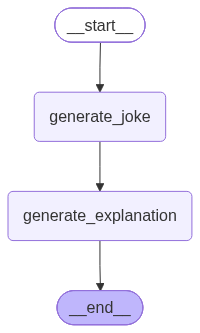

In [33]:
graph = StateGraph(JokeState)

graph.add_node("generate_joke", generate_joke)
graph.add_node("generate_explanation", generate_explanation)

graph.add_edge(START, "generate_joke")
graph.add_edge("generate_joke", "generate_explanation")
graph.add_edge("generate_explanation", END)

# checkpointer object of InMemorySaver type, it create persistence
checkpointer = InMemorySaver()

workflow = graph.compile(checkpointer=checkpointer)

workflow

In [34]:
config1 = {"configurable": {"thread_id": "1"}}

In [35]:
workflow.invoke({"topic":"pizza"}, config=config1)

{'topic': 'pizza',
 'joke': 'Why did the pizza apply for a job?\n\nBecause it kneaded the dough! 🍕😄',
 'explanation': '**The Joke**\n\n> *Why did the pizza apply for a job?*  \n> *Because it kneaded the dough! 🍕😄*\n\n---\n\n## 1. The Structure of the Joke  \n\n1. **Set‑up** – “Why did the pizza apply for a job?”  \n   - This invites the listener to think of a logical, perhaps absurd reason why a **pizza** (an inanimate food item) would need employment. It creates a brief moment of curiosity.\n\n2. **Punchline** – “Because it **kneaded** the dough!”  \n   - The humor arrives in the answer, which flips the expectation with a **pun** (a play on words). The punchline resolves the set‑up in a surprising, clever way.\n\n---\n\n## 2. Why It Works: The Wordplay  \n\n| Word | Primary meaning in the joke | Secondary (pun) meaning |\n|------|----------------------------|--------------------------|\n| **Kneaded** | The action of pressing and folding **pizza dough** to develop gluten before baking.

In [36]:
# final state value
workflow.get_state(config1)

StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza apply for a job?\n\nBecause it kneaded the dough! 🍕😄', 'explanation': '**The Joke**\n\n> *Why did the pizza apply for a job?*  \n> *Because it kneaded the dough! 🍕😄*\n\n---\n\n## 1. The Structure of the Joke  \n\n1. **Set‑up** – “Why did the pizza apply for a job?”  \n   - This invites the listener to think of a logical, perhaps absurd reason why a **pizza** (an inanimate food item) would need employment. It creates a brief moment of curiosity.\n\n2. **Punchline** – “Because it **kneaded** the dough!”  \n   - The humor arrives in the answer, which flips the expectation with a **pun** (a play on words). The punchline resolves the set‑up in a surprising, clever way.\n\n---\n\n## 2. Why It Works: The Wordplay  \n\n| Word | Primary meaning in the joke | Secondary (pun) meaning |\n|------|----------------------------|--------------------------|\n| **Kneaded** | The action of pressing and folding **pizza dough** to develop gl

In [37]:
# workflow state history, it will return a list of all the states that have been executed in the workflow
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza apply for a job?\n\nBecause it kneaded the dough! 🍕😄', 'explanation': '**The Joke**\n\n> *Why did the pizza apply for a job?*  \n> *Because it kneaded the dough! 🍕😄*\n\n---\n\n## 1. The Structure of the Joke  \n\n1. **Set‑up** – “Why did the pizza apply for a job?”  \n   - This invites the listener to think of a logical, perhaps absurd reason why a **pizza** (an inanimate food item) would need employment. It creates a brief moment of curiosity.\n\n2. **Punchline** – “Because it **kneaded** the dough!”  \n   - The humor arrives in the answer, which flips the expectation with a **pun** (a play on words). The punchline resolves the set‑up in a surprising, clever way.\n\n---\n\n## 2. Why It Works: The Wordplay  \n\n| Word | Primary meaning in the joke | Secondary (pun) meaning |\n|------|----------------------------|--------------------------|\n| **Kneaded** | The action of pressing and folding **pizza dough** to develop g

In [38]:
config2 = {"configurable": {"thread_id": "2"}}
workflow.invoke({"topic":"chicken"}, config=config2)

{'topic': 'chicken',
 'joke': 'Why did the chicken join a band?\n\nBecause it already had the drumsticks! 🐔🥁',
 'explanation': '**Explanation of the joke**\n\n- **Setup:** “Why did the chicken join a band?”  \n  This line primes the listener to think about a reason a chicken might become part of a musical group. It creates an expectation that the punchline will involve some clever or unexpected musical connection.\n\n- **Punchline:** “Because it already had the drum‑sticks! 🐔🥁”  \n  The humor comes from a **play on words** (a pun) that hinges on the two meanings of “drumsticks”:\n\n  1. **Drumsticks (musical instrument)** – In a band, a drummer uses a pair of wooden sticks called drumsticks to hit the drums. Having drumsticks is a prerequisite for playing the drums.\n\n  2. **Drumsticks (food)** – The term “drumsticks” is also a colloquial name for a chicken’s leg (the part that looks like a small drum). When you buy chicken, the leg portion is often sold as “drumsticks.”\n\n- **Why it

In [39]:
workflow.get_state(config=config2)

StateSnapshot(values={'topic': 'chicken', 'joke': 'Why did the chicken join a band?\n\nBecause it already had the drumsticks! 🐔🥁', 'explanation': '**Explanation of the joke**\n\n- **Setup:** “Why did the chicken join a band?”  \n  This line primes the listener to think about a reason a chicken might become part of a musical group. It creates an expectation that the punchline will involve some clever or unexpected musical connection.\n\n- **Punchline:** “Because it already had the drum‑sticks! 🐔🥁”  \n  The humor comes from a **play on words** (a pun) that hinges on the two meanings of “drumsticks”:\n\n  1. **Drumsticks (musical instrument)** – In a band, a drummer uses a pair of wooden sticks called drumsticks to hit the drums. Having drumsticks is a prerequisite for playing the drums.\n\n  2. **Drumsticks (food)** – The term “drumsticks” is also a colloquial name for a chicken’s leg (the part that looks like a small drum). When you buy chicken, the leg portion is often sold as “drumsti

In [40]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'chicken', 'joke': 'Why did the chicken join a band?\n\nBecause it already had the drumsticks! 🐔🥁', 'explanation': '**Explanation of the joke**\n\n- **Setup:** “Why did the chicken join a band?”  \n  This line primes the listener to think about a reason a chicken might become part of a musical group. It creates an expectation that the punchline will involve some clever or unexpected musical connection.\n\n- **Punchline:** “Because it already had the drum‑sticks! 🐔🥁”  \n  The humor comes from a **play on words** (a pun) that hinges on the two meanings of “drumsticks”:\n\n  1. **Drumsticks (musical instrument)** – In a band, a drummer uses a pair of wooden sticks called drumsticks to hit the drums. Having drumsticks is a prerequisite for playing the drums.\n\n  2. **Drumsticks (food)** – The term “drumsticks” is also a colloquial name for a chicken’s leg (the part that looks like a small drum). When you buy chicken, the leg portion is often sold as “drumst

#### Fault Tolerance 

```
START ---> step 1 ---> step 2 ---> step 3 --> END
                         |
                    (delat 30sec)
                         |
                   (adding manual keyboard 
                intrupt to stop the execution)
                         |
                    Resume from here  
                      
```

In [5]:
import time

In [13]:
# 1. Define the state
class CrashState(TypedDict):
    input: str
    step1: str
    step2: str
    step3: str

In [14]:
# 2. Define steps
def step_1(state: CrashState):
    print("✅ Step 1 executed")
    return {"step1": "done", "input": state["input"]}


def step_2(state: CrashState):
    print("⌛ Step 2 handing... now manually interrupt fron the notebook toolbar[stop button]")
    time.sleep(30) # Simulation long-running hand
    return {"step2": "done"}


def step_3(state: CrashState):
    print("✅ Step 3 executed")
    return {"step3": "done"}

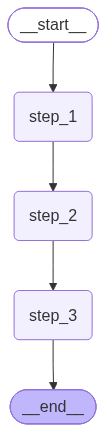

In [15]:
# 3. Build the graph

graph = StateGraph(CrashState)

graph.add_node("step_1", step_1)
graph.add_node("step_2", step_2)
graph.add_node("step_3", step_3)

graph.add_edge(START, "step_1")
graph.add_edge("step_1", "step_2")
graph.add_edge("step_2", "step_3")
graph.add_edge("step_3", END)

checkpointer = InMemorySaver()

workflow = graph.compile(checkpointer=checkpointer)

workflow

In [ ]:
try:
    print("▶️ Running workflow: Please manually interrupt the kernel during step 2...")
    workflow.invoke({'input': "start"}, config={"configurable": {"thread_id": "1"}})
except KeyboardInterrupt:
    print("❗Kernel manually interrupted")

▶️ Running workflow: Please manually interrupt the kernel during step 2...
✅ Step 1 executed
⌛ Step 2 handing... now manually interrupt fron the notebook toolbar[stop button]
Kernel manually interrupted


In [17]:
workflow.get_state({"configurable": {"thread_id": "1"}})

StateSnapshot(values={'input': 'start', 'step1': 'done'}, next=('step_2',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d09-b3b8-6862-8001-ebb7342315a0'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-11-24T06:30:56.877952+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d09-b3b1-68de-8000-a02bc33ea952'}}, tasks=(PregelTask(id='48ebddd7-84f1-5880-ebd7-a7979dba8cde', name='step_2', path=('__pregel_pull', 'step_2'), error=None, interrupts=(), state=None, result=None),), interrupts=())

In [18]:
list(workflow.get_state_history({"configurable": {"thread_id": "1"}}))

[StateSnapshot(values={'input': 'start', 'step1': 'done'}, next=('step_2',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d09-b3b8-6862-8001-ebb7342315a0'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-11-24T06:30:56.877952+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d09-b3b1-68de-8000-a02bc33ea952'}}, tasks=(PregelTask(id='48ebddd7-84f1-5880-ebd7-a7979dba8cde', name='step_2', path=('__pregel_pull', 'step_2'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'input': 'start'}, next=('step_1',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d09-b3b1-68de-8000-a02bc33ea952'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-11-24T06:30:56.875096+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d09-b3ac

In [19]:
# 6. Re-run to show fault tolerance resume
# input -> None (it means we resume workflow)
final_state = workflow.invoke(None, config={"configurable": {"thread_id": "1"}})
print("\n ✅Final State", final_state)

⌛ Step 2 handing... now manually interrupt fron the notebook toolbar[stop button]
✅ Step 3 executed

 ✅Final State {'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}


In [20]:
workflow.get_state({"configurable": {"thread_id": "1"}})

StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d0d-ac10-6c54-8003-3796506b84dd'}}, metadata={'source': 'loop', 'step': 3, 'parents': {}}, created_at='2026-11-24T06:32:43.449419+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d0d-ac0b-6a2a-8002-aa3ccc6251a2'}}, tasks=(), interrupts=())

In [21]:
list(workflow.get_state_history({"configurable": {"thread_id": "1"}}))

[StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done', 'step3': 'done'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d0d-ac10-6c54-8003-3796506b84dd'}}, metadata={'source': 'loop', 'step': 3, 'parents': {}}, created_at='2026-11-24T06:32:43.449419+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d0d-ac0b-6a2a-8002-aa3ccc6251a2'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done'}, next=('step_3',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d0d-ac0b-6a2a-8002-aa3ccc6251a2'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-11-24T06:32:43.447310+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d09-b3b8-6862-8001-ebb7342315a0'}}, tasks=(PregelTask(id='47504a21-3e9d-ea05-ad83-afd0ff81f9b3', name='s

#### Time Travel

In [41]:
workflow.get_state({"configurable": {"thread_id": "2", "checkpoint_id": "1f1e7d6c-039e-64c3-8000-d126597fad3c"}})

StateSnapshot(values={'topic': 'chicken'}, next=('generate_joke',), config={'configurable': {'thread_id': '2', 'checkpoint_id': '1f1e7d6c-039e-64c3-8000-d126597fad3c'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-11-24T07:14:55.923285+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d6c-0398-63b2-bfff-62b31e4bb802'}}, tasks=(PregelTask(id='ddae089f-0d77-1294-65bd-9c7aac1ca1f7', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result={'joke': 'Why did the chicken join a band?\n\nBecause it already had the drumsticks! 🐔🥁'}),), interrupts=())

In [42]:
workflow.invoke(None, {"configurable": {"thread_id": "2", "checkpoint_id": "1f1e7d6c-039e-64c3-8000-d126597fad3c"}})

{'topic': 'chicken',
 'joke': 'Why did the chicken join a band?\n\nBecause it already had the drumsticks! 🐔🥁',
 'explanation': '**Explanation of the joke**\n\n| Element of the joke | What it means literally | What it means figuratively (the punch‑line) |\n|---------------------|-------------------------|---------------------------------------------|\n| **“Why did the chicken join a band?”** | Sets up a classic “knock‑knock/why‑did‑the‑…?” style riddle. The listener expects a funny or absurd reason why a chicken would want to be part of a musical group. | Same as the literal set‑up – it primes us for a clever twist. |\n| **“Because it already had the drumsticks!”** | *Drumsticks* are the two long, thin pieces of meat that come from a chicken’s legs. Anyone who’s ever bought chicken at the grocery store knows this. | In a band, a *drumstick* is also the stick a drummer uses to hit the drums. The joke hinges on the word **“drumsticks”** having two completely different meanings that happen

In [46]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'samosa'}, next=('generate_joke',), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d72-a123-6e26-8001-f73e316bdd6a'}}, metadata={'source': 'update', 'step': 1, 'parents': {}}, created_at='2026-11-24T07:17:53.501909+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d6c-039e-64c3-8000-d126597fad3c'}}, tasks=(PregelTask(id='b34e72d0-e824-be37-b048-e91241a55f64', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'topic': 'samosa'}, next=('generate_joke',), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d71-aef8-6ca8-8001-0c9d7fbf3ec0'}}, metadata={'source': 'update', 'step': 1, 'parents': {}}, created_at='2026-11-24T07:17:28.108728+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id

#### Updating State

we can update the value of any checkpoint

In [48]:
# changed topic from chicken to samosa
workflow.update_state({"configurable": {"thread_id": "2", "checkpoint_id": "1f1e7d6c-039e-64c3-8000-d126597fad3c", "checkpoint_ns": ""}}, {'topic':'samosa'})

{'configurable': {'thread_id': '2',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1e7d74-74ad-6854-8001-c9d25b18adf5'}}

In [49]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'samosa'}, next=('generate_joke',), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d74-74ad-6854-8001-c9d25b18adf5'}}, metadata={'source': 'update', 'step': 1, 'parents': {}}, created_at='2026-11-24T07:18:42.526791+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d6c-039e-64c3-8000-d126597fad3c'}}, tasks=(PregelTask(id='053821c6-3312-e16f-58e0-1e4e55746732', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'topic': 'samosa'}, next=('generate_joke',), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e7d72-a123-6e26-8001-f73e316bdd6a'}}, metadata={'source': 'update', 'step': 1, 'parents': {}}, created_at='2026-11-24T07:17:53.501909+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id

In [51]:
# pass updated checkpoint id of samosa to generate joke and explnation
workflow.invoke(None, {"configurable": {"thread_id": "2", "checkpoint_id": "1f1e7d74-74ad-6854-8001-c9d25b18adf5"}})

{'topic': 'samosa',
 'joke': 'Why did the samosa go to therapy?  \n\nBecause it was tired of being *filled* with all those secret feelings and just wanted to *crunch* out its emotions!',
 'explanation': '**Explanation of the Joke**\n\n> *Why did the samosa go to therapy?*  \n> *Because it was tired of being **filled** with all those secret feelings and just wanted to **crunch** out its emotions!*\n\n---\n\n### 1. The Surface Story  \nThe joke pretends that a samosa—a fried or baked Indian snack that is usually *filled* with spiced potatoes, peas, meat, or other ingredients—has a life like a human being. In this imagined world the samosa is feeling “over‑filled” with “secret feelings” and decides to see a therapist to “crunch” (i.e., release) those emotions.\n\n---\n\n### 2. Why It’s Funny – The Mechanics of the Humor  \n\n| Humor Technique | How It Works in This Joke |\n|-----------------|---------------------------|\n| **Anthropomorphism** | Giving a food item human traits (the abilit

In [52]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'samosa', 'joke': 'Why did the samosa go to therapy?  \n\nBecause it was tired of being *filled* with all those secret feelings and just wanted to *crunch* out its emotions!', 'explanation': '**Explanation of the Joke**\n\n> *Why did the samosa go to therapy?*  \n> *Because it was tired of being **filled** with all those secret feelings and just wanted to **crunch** out its emotions!*\n\n---\n\n### 1. The Surface Story  \nThe joke pretends that a samosa—a fried or baked Indian snack that is usually *filled* with spiced potatoes, peas, meat, or other ingredients—has a life like a human being. In this imagined world the samosa is feeling “over‑filled” with “secret feelings” and decides to see a therapist to “crunch” (i.e., release) those emotions.\n\n---\n\n### 2. Why It’s Funny – The Mechanics of the Humor  \n\n| Humor Technique | How It Works in This Joke |\n|-----------------|---------------------------|\n| **Anthropomorphism** | Giving a food item huma